# 3.06 — Partición temporal: posibles sesgos y variabilidad de la comparación

**Proyecto:** MiBici — TC5044.10 — Equipo 04
**Autor:** Leonardo Santos García
**Fecha:** 21 de noviembre de 2026

Esta libreta responde a la retroalimentación del profesor sobre la Fase 2: justificar por qué se
mantuvo la partición de datos y explicar si, dada la distribución y la variabilidad de los datos,
puede introducir algún sesgo. Solo lee y mide: no entrena modelos, no cambia el `champion` y no
toca la partición. *Test* ya se evaluó en la Fase 2 (libreta 3.05); aquí solo se mide la
incertidumbre de esa comparación.

## 1. La partición y la retroalimentación anterior

En la Fase 1 el profesor sugirió una validación temporal **progresiva**, como en la industria:
entrenar hasta una fecha de corte, evaluar el periodo siguiente, avanzar el corte y repetir,
usando solo la información disponible en cada momento.

En el contrato de modelado (libreta 3.01, sección 7) el equipo adoptó una **validación híbrida**:

| Elemento | Definición | Relación con la validación progresiva |
|---|---|---|
| Partición cronológica | *train* 2022-01-01 → 2026-05-31; *validation* jun–jul 2026; *test* ago–sep 2026 | Mismo principio: nada se aprende del futuro |
| Ventanas | `window_june`: entrena hasta mayo y evalúa junio; `window_july`: entrena hasta junio y evalúa julio | Son dos pasos de una validación progresiva: el corte avanza un mes |
| Ajuste de hiperparámetros | Solo en la partición de *validation* | Las ventanas se usan con la mejor configuración de cada modelo |
| *Test* | Entrena con *train* + *validation* y evalúa una sola vez | Último paso, reservado para el resultado final |

**Por qué no ventanas progresivas completas:** cada ventana obliga a reentrenar los cuatro bloques
(baseline, Poisson, Random Forest y HGB) con más de diez millones de filas, y la rejilla de
hiperparámetros multiplicaba ese costo. Se mantuvieron dos ventanas mensuales, que sí miden la
estabilidad mes a mes, en lugar de recorrer todo un año.

Las secciones siguientes miden qué sesgos puede introducir esa decisión.

In [1]:
# Libraries: tables, figures and the exported champion
import matplotlib.pyplot as plt
import mlflow.sklearn
import numpy as np
import pandas as pd

# Shared settings and the same functions the modeling pipeline uses
from mibici.config import CHAMPION_EXPORT_DIR, FIGURES_DIR, RANDOM_STATE, SPLITS, TARGET
from mibici.modeling.metrics import evaluate, paired_bootstrap_wape_difference, wape
from mibici.modeling.models import make_model
from mibici.modeling.splits import label_splits, split_summary, train_eval_masks
from mibici.modeling.train import load_modeling_table

# processed_v1 with the history features of the contract (avg_4_weeks, t_168)
table = load_modeling_table()
table["split"] = label_splits(table)
print(f"{len(table):,} rows from {table['hour_start'].min():%Y-%m-%d} to {table['hour_start'].max():%Y-%m-%d}")

2026-11-21 13:33:44.390 -06:00 | INFO     | mibici.config:<module>:12 - PROJ_ROOT path is: /home/watson/projects/mibici


11,949,160 rows from 2022-01-01 to 2026-09-30


## 2. Composición de cada partición

`split_summary` es la misma función que usó el contrato de la Fase 2. Se agregan los días con
eventos extraordinarios, las salidas promedio por día y los meses que cubre cada periodo.

In [2]:
# Size and composition of every period (same function as the Phase 2 contract)
summary = split_summary(table)

# Extra facts per split: event days, mean departures per day and months covered
extra = {}
for name in SPLITS:
    part = table[table["split"] == name]
    days = part["hour_start"].dt.normalize()
    extra[name] = {
        "event_days": days[part["is_extraordinary_event"]].nunique(),
        "departures_per_day": round(part[TARGET].sum() / days.nunique()),
        "months": ", ".join(sorted({f"{m:02d}" for m in part["hour_start"].dt.month})),
    }
summary.join(pd.DataFrame(extra).T, how="left")

,start,end,rows,stations,zero_share,new_cohort_stations,rows_unseen_in_train,rows_without_history,event_days,departures_per_day,months
period,,,,,,,,,,,
train,2022-01-01,2026-05-31 23:00:00,10869060,385,0.422761,12,0.000000,42000,2,11624,"01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12"
validation,2026-06-01,2026-07-31 23:00:00,511960,454,0.487351,86,0.094461,0,0,11655,"06, 07"
test,2026-08-01,2026-09-30 23:00:00,568140,469,0.474598,98,0.180941,0,0,13901,"08, 09"
window_june,2026-06-01,2026-06-30 23:00:00,240200,427,0.485545,59,0.050791,0,NaN,NaN,NaN
window_july,2026-07-01,2026-07-31 23:00:00,271760,453,0.488946,85,0.133059,0,NaN,NaN,NaN


## 3. Cobertura estacional

La demanda de MiBici cambia a lo largo del año. La figura muestra las salidas mensuales y qué
meses evalúa cada periodo.

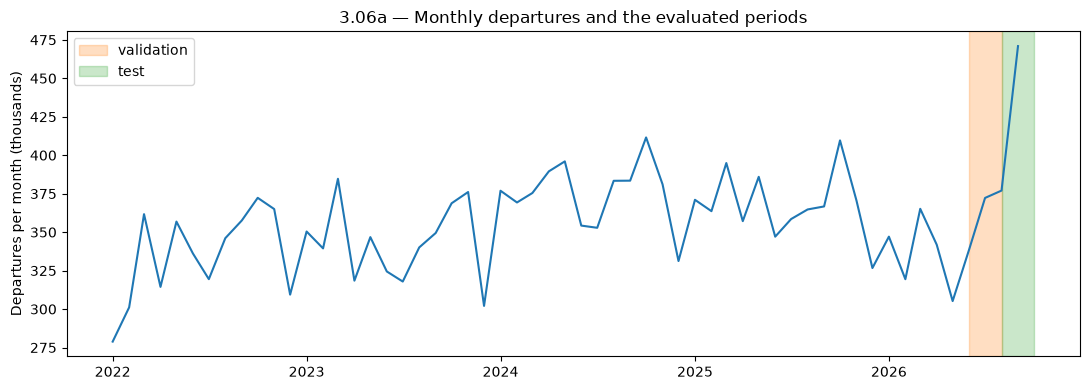

In [3]:
# Monthly departures with the evaluated periods shaded
monthly = table.groupby(table["hour_start"].dt.to_period("M"))[TARGET].sum()
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index.to_timestamp(), monthly.to_numpy() / 1000, color="#1f77b4")
for name, color in (("validation", "#ff7f0e"), ("test", "#2ca02c")):
    start, end = SPLITS[name]
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=color, alpha=0.25, label=name)
ax.set_ylabel("Departures per month (thousands)")
ax.set_title("3.06a — Monthly departures and the evaluated periods")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "3.06a-monthly-departures-and-splits.png", dpi=150)
plt.show()

## 4. Crecimiento de la demanda en los periodos evaluados

Se comparan los meses de *validation* y *test* con los mismos meses del año anterior.

In [4]:
# Same months of 2025 and 2026 and their year-over-year change
months = [pd.Period(f"{year}-{m:02d}") for year in (2025, 2026) for m in (6, 7, 8, 9)]
growth = pd.DataFrame(
    {
        "2025": [monthly[pd.Period(f"2025-{m:02d}")] for m in (6, 7, 8, 9)],
        "2026": [monthly[pd.Period(f"2026-{m:02d}")] for m in (6, 7, 8, 9)],
    },
    index=["June", "July", "August", "September"],
)
growth["change_%"] = (100 * (growth["2026"] / growth["2025"] - 1)).round(1)
growth

,2025,2026,change_%
June,347070,338700,-2.4
July,358531,372243,3.8
August,364752,377023,3.4
September,366714,470925,28.4


## 5. ¿La ventaja del `champion` supera la variación casual?

En *test* el `champion` (HGB, versión 3) obtuvo un WAPE de 0.6066 y el baseline de 0.6227: una
ventaja de 0.016. La pregunta es si esa diferencia es robusta o si otro conjunto de días
parecidos podría invertirla.

**Método: bootstrap pareado por días.**

1. Se toman los 61 días de *test*. Cada remuestreo elige 61 días con reemplazo.
2. Se remuestrean **días completos**, no horas sueltas: las 20 horas de un día comparten clima,
   eventos y errores, así que no son independientes.
3. Ambos modelos se evalúan sobre **los mismos días** remuestreados (comparación pareada): un día
   difícil cuenta contra los dos y no se confunde con ventaja de uno.
4. En cada remuestreo se calcula la diferencia WAPE(`champion`) − WAPE(baseline). Con 2,000
   remuestreos se obtiene el intervalo del 95 % y la proporción de remuestreos donde gana el
   `champion`.

$$\Delta^{*} = \frac{\sum_{d \in D^{*}} \sum_{h} |y_{dh} - \hat{y}^{\,champion}_{dh}| - \sum_{d \in D^{*}} \sum_{h} |y_{dh} - \hat{y}^{\,baseline}_{dh}|}{\sum_{d \in D^{*}} \sum_{h} y_{dh}}$$

donde $D^{*}$ son los días remuestreados, $h$ las horas y estaciones de cada día, $y$ las
salidas observadas y $\hat{y}$ el pronóstico de cada modelo. El `champion` es el modelo exportado
del Model Registry (`models/serving/champion`), el mismo que sirve la API.

In [5]:
# Test rows exactly as in Phase 2 (train + validation -> test) and both forecasts
_, test_mask = train_eval_masks(table, "test")
test = table[test_mask].reset_index(drop=True)
champion = mlflow.sklearn.load_model(str(CHAMPION_EXPORT_DIR))
forecasts = {
    "champion": champion.predict(test),
    # The baseline learns nothing: it returns avg_4_weeks
    "baseline": make_model("baseline").fit(test, test[TARGET]).predict(test),
}
scores = pd.concat({name: evaluate(test, f) for name, f in forecasts.items()}, names=["model"])
scores[["rows", "departures", "wape", "mae", "volume_ratio"]].round(4)

rows  departures    wape     mae  \
model    segment                                                    
champion all                   568140      847948  0.6066  0.9053   
         established_stations  450700      784148  0.5866  1.0205   
         new_station_cohort    117440       63800  0.8525  0.4631   
baseline all                   568140      847948  0.6227  0.9294   
         established_stations  450700      784148  0.5968  1.0384   
         new_station_cohort    117440       63800  0.9409  0.5112   

                               volume_ratio  
model    segment                             
champion all                         0.7195  
         established_stations        0.7320  
         new_station_cohort          0.5651  
baseline all                         0.8956  
         established_stations        0.9003  
         new_station_cohort          0.8371

In [6]:
# Paired bootstrap of whole days: WAPE(champion) - WAPE(baseline) on the same resampled days
result = paired_bootstrap_wape_difference(
    test["hour_start"], test[TARGET], forecasts["champion"], forecasts["baseline"],
    n_boot=2000, seed=RANDOM_STATE,
)
pd.Series(result).to_frame("value")

,value
difference,-0.016158
ci_low,-0.024331
ci_high,-0.008841
share_a_better,1.000000
days,61.000000
n_boot,2000.000000


Para ver la variabilidad mes a mes dentro de *test*, se calcula también el WAPE de cada modelo
en agosto y en septiembre.

In [7]:
# WAPE of each model in each test month
month = test["hour_start"].dt.month.map({8: "August", 9: "September"})
by_month = pd.DataFrame(
    {
        name: [wape(test.loc[month == m, TARGET], f[month == m]) for m in ("August", "September")]
        for name, f in forecasts.items()
    },
    index=["August", "September"],
)
by_month["champion_minus_baseline"] = by_month["champion"] - by_month["baseline"]
by_month.round(4)

,champion,baseline,champion_minus_baseline
August,0.6145,0.6468,-0.0323
September,0.6002,0.6034,-0.0032


## 6. Conclusiones

**¿Por qué se mantuvo la partición?** Es cronológica (nada se aprende del futuro), reproduce el
uso real del modelo (con lo observado hasta el día D se pronostica D+1) y sus dos ventanas
mensuales son dos pasos de una validación progresiva: el corte avanza un mes y se vuelve a
evaluar. Recorrer un año completo con ventanas progresivas multiplicaba el costo de entrenar los
cuatro bloques con más de diez millones de filas; las dos ventanas dieron la medida de
estabilidad que pedía la regla de candidato.

**¿Puede introducir sesgo?** No hay fuga de información, pero sí límites de cobertura que
condicionan cómo leer los resultados:

| Posible sesgo | Evidencia (esta libreta) | Efecto en los resultados | Mitigación o limitación |
|---|---|---|---|
| Cobertura estacional | *Validation* y *test* solo cubren junio–septiembre; *train* cubre los 12 meses | Las métricas valen para verano y temporada de lluvias; no prueban invierno ni diciembre | Limitación. Mejora futura: validación progresiva a lo largo de un año completo |
| Crecimiento de la demanda en *test* | Septiembre de 2026: +28.4 % contra septiembre de 2025; salidas por día: *validation* 11,655 y *test* 13,901 (+19 %) | *Test* es más difícil que el periodo donde se eligió el modelo. En septiembre la ventaja del `champion` casi desaparece (−0.003) y su volumen pronosticado queda en 72 % del observado | Es un cambio real de distribución, no un error de partición: lo vigila el monitoreo de drift de la Entrega Final |
| Estaciones que *train* no vio | 9.4 % de las filas de *validation* y 18.1 % de las de *test* son de estaciones sin filas en *train* | Arranque en frío: en la cohorte nueva el `champion` tiene WAPE 0.853 (baseline 0.941) y pronostica 57 % del volumen | Mitigado: la cohorte nueva se reporta por separado desde la Fase 2 |
| Sin eventos extraordinarios | 0 días de evento en *validation* y en *test* (2 en *train*) | Los resultados no dicen nada del desempeño en días de evento | Limitación. El escenario de cambio de concepto del drift (libreta 4.01) simula la caída de un día de evento |
| Variabilidad de la comparación | Bootstrap pareado por días: diferencia −0.0162, IC 95 % [−0.0243, −0.0088]; el `champion` gana en el 100 % de 2,000 remuestreos | La ventaja sobre el baseline es robusta en los días de *test*, aunque modesta en tamaño y concentrada en agosto (−0.032 contra −0.003 en septiembre) | Se reporta junto con el tamaño del efecto, no solo el signo |

**En resumen:** la partición es válida para elegir el modelo sin fuga de información y la ventaja
del `champion` no se explica por azar. Su alcance está acotado a la temporada evaluada, y el
crecimiento de septiembre muestra que la ventaja puede reducirse cuando la demanda cambia:
precisamente lo que el monitoreo de drift debe detectar a tiempo.